## Imports 

In [1]:
# PyTorch: tensores, redes neuronales, funciones y optimizadores
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split, Subset
from torchvision.datasets import ImageFolder

# Visión artificial
import torchvision
import torchvision.transforms as transforms

# Cálculo numérico, gráficas y utilidades
import random
from pathlib import Path

# Imports para la configuración del dataset
import random
import shutil
from pathlib import Path

# Cálculo numérico, gráficas y utilidades
import numpy as np
import matplotlib.pyplot as plt
import random
import time

from PIL import Image, ImageFile
import csv
from datetime import datetime
from collections import Counter

## 1. Configuración y creación del dataset

En esta sección se construye el dataset de trabajo a partir del dataset original descargado (`ORIGEN`), dejando el resultado en `DESTINO` con la estructura `train/` y `val/`, una subcarpeta por emoción.

**Parámetros de configuración**

- **`IMGS_POR_CLASE`:** número máximo de imágenes válidas que se usan por clase.
- **`PROP_TRAIN = 0.8`:** el 80 % de las imágenes va a entrenamiento y el 20 % a validación.
- **`SEED`:** semilla del reparto aleatorio, para que sea reproducible.
- **`MIN_LADO`:** se descartan las imágenes con algún lado menor de 32 píxeles.
- **`EXTENSIONES`:** formatos de imagen aceptados.

**Funciones**

- **`imagen_valida`:** comprueba que la imagen se puede abrir y decodificar completa. `verify()` detecta archivos corruptos, pero no los truncados, así que se reabre y se cargan los píxeles con `load()`. También descarta imágenes demasiado pequeñas.
- **`preparar_clase`:** mezcla aleatoriamente las imágenes de una clase, se queda con las válidas hasta alcanzar `IMGS_POR_CLASE` y las reparte entre train y val.
- **`copiar`:** copia las imágenes a la carpeta de destino, renombrándolas si hubiera nombres repetidos para no sobrescribir ninguna.
- **`main`:** recorre todas las clases, aplica lo anterior y muestra cuántas imágenes quedan en cada partición y cuántas se descartaron.

Si `DESTINO` ya existe, no se vuelve a generar, para no mezclar datos antiguos con nuevos. Para regenerarlo hay que borrar esa carpeta.

In [14]:
ORIGEN = Path("./datasets/archive/Emotions-Dataset")  
DESTINO = Path("./datasets/My_dataset")        
IMGS_POR_CLASE = 3000               # nº de imágenes válidas a usar por clase
PROP_TRAIN = 0.8                    # 80% train, 20% val
SEED = 42                        # para que el reparto sea reproducible
MIN_LADO = 32                       # descarta imágenes absurdamente pequeñas
EXTENSIONES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CLASES = ["angry", "happy", "sad", "surprised"]

# Importante: False para que las imágenes truncadas lancen error al cargarlas
ImageFile.LOAD_TRUNCATED_IMAGES = False

#if DESTINO.exists():
#   shutil.rmtree(DESTINO)

def imagen_valida(ruta: Path) -> bool:
    """True si la imagen se puede abrir y decodificar COMPLETA."""
    try:
        # 1) verify() detecta archivos corruptos en la cabecera/estructura
        with Image.open(ruta) as img:
            img.verify()
        # 2) verify() no detecta truncados: hay que reabrir y cargar los píxeles
        with Image.open(ruta) as img:
            img.load()
            if min(img.size) < MIN_LADO:
                return False
        return True
    except Exception:
        return False


def preparar_clase(carpeta_clase: Path, rng: random.Random):
    candidatas = [p for p in carpeta_clase.iterdir()
                  if p.is_file() and p.suffix.lower() in EXTENSIONES]
    rng.shuffle(candidatas)

    validas, descartadas = [], 0
    for ruta in candidatas:
        if len(validas) >= IMGS_POR_CLASE:
            break
        if imagen_valida(ruta):
            validas.append(ruta)
        else:
            descartadas += 1

    if len(validas) < IMGS_POR_CLASE:
        print(f"  ⚠ Solo se encontraron {len(validas)} imágenes válidas "
              f"(se pedían {IMGS_POR_CLASE})")

    n_train = int(len(validas) * PROP_TRAIN)
    return validas[:n_train], validas[n_train:], descartadas


def copiar(imagenes, carpeta_destino: Path):
    carpeta_destino.mkdir(parents=True, exist_ok=True)
    for ruta in imagenes:
        destino = carpeta_destino / ruta.name
        # evita sobrescribir si hubiera dos archivos con el mismo nombre
        i = 1
        while destino.exists():
            destino = carpeta_destino / f"{ruta.stem}_{i}{ruta.suffix}"
            i += 1
        shutil.copy2(ruta, destino)


def main():
    if not ORIGEN.is_dir():
        raise SystemExit(f"No existe la carpeta de origen: {ORIGEN.resolve()}")

    if DESTINO.exists():
        raise SystemExit(f"{DESTINO} ya existe. Bórrala o cambia DESTINO "
                         "para no mezclar datos antiguos.")

    rng = random.Random(SEED)
    disponibles = sorted(p.name for p in ORIGEN.iterdir() if p.is_dir())
    print(f"Carpetas disponibles en ORIGEN: {disponibles}")

    faltan = [c for c in CLASES if c not in disponibles]
    if faltan:
        raise SystemExit(f"Estas clases no existen en ORIGEN: {faltan}. "
                         f"Revisa los nombres en CLASES.")

    clases = [ORIGEN / c for c in CLASES]
    print(f"Clases encontradas: {[c.name for c in clases]}\n")

    for carpeta in clases:
        print(f"Procesando '{carpeta.name}'...")
        train, val, malas = preparar_clase(carpeta, rng)
        copiar(train, DESTINO / "train" / carpeta.name)
        copiar(val, DESTINO / "val" / carpeta.name)
        print(f"  train: {len(train)} | val: {len(val)} | "
              f"descartadas por corruptas/recortadas: {malas}")

    print(f"\nListo. Dataset creado en: {DESTINO.resolve()}")


if __name__ == "__main__":
    main()

Carpetas disponibles en ORIGEN: ['angry', 'happy', 'sad', 'surprised']
Clases encontradas: ['angry', 'happy', 'sad', 'surprised']

Procesando 'angry'...
  ⚠ Solo se encontraron 1275 imágenes válidas (se pedían 3000)
  train: 1020 | val: 255 | descartadas por corruptas/recortadas: 0
Procesando 'happy'...
  ⚠ Solo se encontraron 1275 imágenes válidas (se pedían 3000)
  train: 1020 | val: 255 | descartadas por corruptas/recortadas: 0
Procesando 'sad'...
  ⚠ Solo se encontraron 1275 imágenes válidas (se pedían 3000)
  train: 1020 | val: 255 | descartadas por corruptas/recortadas: 0
Procesando 'surprised'...
  ⚠ Solo se encontraron 1275 imágenes válidas (se pedían 3000)
  train: 1020 | val: 255 | descartadas por corruptas/recortadas: 0

Listo. Dataset creado en: C:\Users\casba\OneDrive\universidad\CuartoAño\FSI\CNN\PRACTICA2_FSI_CNN\datasets\My_dataset


## 2. Comprobación de las carpetas train y val

Una vez creado el dataset, se comprueba que tiene la estructura que espera `ImageFolder`:

- **`DATA_DIR`:** ruta a la carpeta que contiene `train` y `val`. Se usa en el resto del notebook para cargar los datos.
- **Recuento por clase:** para cada partición se muestra el número de imágenes de cada emoción. Sirve para verificar que el reparto es el esperado (aprox. 80 % en train y 20 % en val) y que las clases están equilibradas.

Si falta alguna carpeta, se muestra un aviso. En ese caso hay que revisar la ruta o volver a generar el dataset de la sección 1.

In [3]:
DATA_DIR = Path("./datasets/My_dataset")  # CAMBIA esta ruta para tu ordenador

if DATA_DIR.exists():
    for split in ("train", "val"):
        folder = DATA_DIR / split
        print(f"\n{split}:")
        if folder.exists():
            for cls in sorted(p for p in folder.iterdir() if p.is_dir()):
                count = sum(1 for f in cls.iterdir() if f.is_file())
                print(f"  {cls.name}: {count} archivos")
        else:
            print("  No existe:", folder)
else:
    print("No se encuentra", DATA_DIR.resolve(), "- crea la estructura o cambia DATA_DIR.")


train:
  angry: 2400 archivos
  happy: 2400 archivos
  sad: 2400 archivos
  surprised: 2400 archivos

val:
  angry: 600 archivos
  happy: 600 archivos
  sad: 600 archivos
  surprised: 600 archivos


## 3. Preparación de las imágenes

Antes de entrar en la red, todas las imágenes deben tener el mismo formato y tamaño. Para ello se definen dos conjuntos de transformaciones con `transforms.Compose`, que se aplican en orden a cada imagen.

**Transformaciones comunes (train y val)**

- **`convert("RGB")`:** unifica los canales. Algunas imágenes pueden estar en escala de grises o tener transparencia, y la red espera siempre 3 canales.
- **`Resize((128, 128))`:** redimensiona todas las imágenes a 128×128 píxeles, porque la red necesita entradas de tamaño fijo.
- **`ToTensor()`:** convierte la imagen en un tensor de PyTorch con forma `(canales, alto, ancho)` y valores entre 0 y 1.
- **`Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))`:** centra los valores en el rango [-1, 1], lo que suele facilitar y estabilizar el entrenamiento.

**Data augmentation (solo en train)**

- **`RandomHorizontalFlip(p=0.5)`:** voltea la imagen horizontalmente con un 50 % de probabilidad.
- **`RandomRotation(10)`:** la gira aleatoriamente hasta 10° en cualquier sentido.

Estas variaciones aleatorias generan ejemplos ligeramente distintos en cada epoch, lo que ayuda a que el modelo generalice mejor y reduce el riesgo de sobreajuste. En **validación no se aplican**, para evaluar siempre sobre las imágenes tal cual y poder comparar resultados entre epochs.

In [4]:
IMG_SIZE = 128

train_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),    # recorta un trozo al azar (80-100 %) y lo redimensiona
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),          # cambia brillo y contraste
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.1)),           # tapa un rectángulo pequeño
])

val_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))
])
print("Transformaciones definidas.")

Transformaciones definidas.


## 4. Cargar las carpetas con `ImageFolder`

En esta sección se cargan las imágenes de `train` y `val` y se preparan para alimentar a la red.

**Hiperparámetros**

- **`BATCH_SIZE = 16`:** número de imágenes que se procesan juntas antes de actualizar los pesos.
- **`EPOCHS = 22`:** número de pasadas completas por el conjunto de entrenamiento.
- **`LEARNING_RATE = 1e-3`:** tamaño del paso con el que el optimizador ajusta los pesos.

**Carga de datos**

- **`ImageFolder`:** crea un dataset a partir de la estructura de carpetas. Cada subcarpeta es una clase (emoción) y su nombre se usa como etiqueta. Aplica a cada imagen las transformaciones definidas en la sección 3.
- **`DataLoader`:** entrega las imágenes en lotes (*batches*). En entrenamiento usa `shuffle=True` para que el orden cambie en cada epoch y el modelo no aprenda el orden de los datos; en validación no hace falta mezclar.
- **Comprobaciones:** se verifica que las clases de `train` y `val` coinciden, y se extrae un lote de prueba para ver sus formas: `(batch, canales, alto, ancho)` para las imágenes y `(batch,)` para las etiquetas.

In [7]:
BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 1e-3

train_dir, val_dir = DATA_DIR / "train", DATA_DIR / "val"
if train_dir.exists() and val_dir.exists():
    train_ds = ImageFolder(str(train_dir), transform=train_transform)
    val_ds = ImageFolder(str(val_dir), transform=val_transform)
    print("Clases train:", train_ds.classes)
    print("Clases val:", val_ds.classes)
    assert train_ds.classes == val_ds.classes, "Las clases deben coincidir en train y val."
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    xb, yb = next(iter(train_loader))
    print("Forma del lote:", tuple(xb.shape))  # (batch, canales, alto, ancho)
    print("Forma de etiquetas:", tuple(yb.shape))
else:
    print("Crea mi_dataset/train y mi_dataset/val, o modifica DATA_DIR.")



Clases train: ['angry', 'happy', 'sad', 'surprised']
Clases val: ['angry', 'happy', 'sad', 'surprised']
Forma del lote: (32, 3, 128, 128)
Forma de etiquetas: (32,)


## 5. Semillas y selección de GPU/CPU

Antes de entrenar se configuran dos aspectos del entorno:

- **Semillas aleatorias (`SEED = 42`):** el entrenamiento incluye procesos aleatorios (inicialización de los pesos, orden de los batches, transformaciones de *data augmentation*). Fijar la misma semilla en `random`, `numpy` y `torch` hace que los experimentos sean **reproducibles**: al repetirlos se obtienen resultados muy similares, lo que permite comparar modelos con justicia.
- **Dispositivo (`DEVICE`):** se usa la **GPU** (`cuda`) si está disponible, porque acelera mucho el entrenamiento; si no, se usa la **CPU**. Todos los tensores y el modelo deben enviarse al mismo dispositivo con `.to(DEVICE)`.


In [8]:
# Semillas para que los experimentos sean reproducibles
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Selección automática de GPU si está disponible; si no, CPU
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Dispositivo:", DEVICE)

PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132
Dispositivo: cuda


## 7. CNN básica

En esta sección se define la arquitectura de la red convolucional (`CNNBasica`), formada por dos bloques:

**1. Extractor de características (`features`)**

Dos capas convolucionales que aprenden filtros para detectar patrones en la imagen (bordes, texturas, formas). Cada una va seguida de una activación **ReLU** y un **max pooling 2×2**, que reduce a la mitad el alto y el ancho.

- `Conv2d(3 → 16)` + pooling: la imagen de 3×128×128 pasa a 16×64×64.
- `Conv2d(16 → 32)` + pooling: pasa a 32×32×32.

**2. Clasificador (`classifier`)**

- `Flatten`: convierte los 32×32×32 = 32.768 valores en un único vector.
- `Linear(32768 → 128)` + ReLU: capa densa que combina las características extraídas.
- `Linear(128 → num_classes)`: capa final que produce una puntuación (*logit*) por cada emoción. La clase predicha es la de mayor puntuación.


In [ ]:
class CNNBasica(nn.Module):
    def __init__(self, num_classes=4, dropout=0.0):
        super().__init__()

        def bloque(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, 3, padding=1),
                nn.BatchNorm2d(c_out),
                nn.ReLU(),
                nn.Conv2d(c_out, c_out, 3, padding=1),
                nn.BatchNorm2d(c_out),
                nn.ReLU(),
                nn.Conv2d(c_out, c_out, 3, padding=1),
                nn.BatchNorm2d(c_out),
                nn.ReLU(),
                nn.Conv2d(c_out, c_out, 3, padding=1),
                nn.BatchNorm2d(c_out),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(
            bloque(3, 32),     # 128 -> 64
            bloque(32, 64),    # 64 -> 32
            bloque(64, 128),   # 32 -> 16
            bloque(128, 256),  # 16 -> 8
        )
        self.pool_global = nn.AdaptiveAvgPool2d(1)   # 256 x 8 x 8 -> 256 x 1 x 1
        self.clasificador = nn.Sequential(
            nn.Flatten(),                            # -> 256
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool_global(x)
        return self.clasificador(x)


model = CNNBasica().to(DEVICE)
print(model)

# Comprobamos el recorrido de una imagen.
with torch.no_grad():
    ejemplo = torch.randn(1, 3, 128, 128).to(DEVICE)
    logits = model(ejemplo)
print("Forma de salida:", logits.shape)          # debe salir torch.Size([1, 4])
print("Parámetros entrenables:", sum(p.numel() for p in model.parameters() if p.requires_grad))   # ~1.175.204

CNNBasica(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
      (6): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (7): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (8): ReLU()
      (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 

## 8. Entrenamiento, validación, batches, epochs y almacenamiento del mejor modelo

En esta sección se definen las funciones que entrenan la red y evalúan su rendimiento.

- **`accuracy_from_logits`:** calcula cuántas predicciones son correctas en un batch, tomando como predicción la clase con mayor puntuación.
- **`run_epoch`:** recorre todo un conjunto de imágenes (*batch* a *batch*) y devuelve la loss media, el accuracy y la loss de cada batch. Si recibe un optimizador, funciona en **modo entrenamiento**: calcula el error, lo propaga hacia atrás (`backward`) y actualiza los pesos. Si no lo recibe, funciona en **modo validación**: solo evalúa, sin modificar los pesos y sin calcular gradientes.
- **`train_model`:** repite el proceso durante varias *epochs*. En cada una entrena con las imágenes de `train`, evalúa con las de `val` y guarda los resultados en un historial (`history`), que luego se usa para dibujar las curvas.

Además, se guarda un checkpoint en la carpeta `modelos/`:

- **`_mejor.pt`:** el modelo con mejor accuracy de validación hasta el momento.

Cada checkpoint incluye también el orden de las clases y el historial, necesarios para interpretar las predicciones y repetir las gráficas sin reentrenar.

### 9. Curvas de loss y accuracy por epoch

Estas gráficas muestran cómo evoluciona el entrenamiento a lo largo de las epochs, comparando los resultados sobre las imágenes de **entrenamiento** (con las que el modelo ajusta sus pesos) y sobre las de **validación** (que no se usan para aprender).

- **Loss (cross-entropy):** mide cuánto se equivocan las predicciones del modelo. Cuanto más baja, mejor.
- **Accuracy:** porcentaje de imágenes clasificadas correctamente.

Comparar ambas curvas permite saber si el modelo generaliza bien. Si la loss de entrenamiento baja pero la de validación se estanca o sube, el modelo está memorizando los ejemplos vistos (**sobreajuste** u *overfitting*) en lugar de aprender patrones generales.

### 10. Loss por batch

Esta gráfica representa la pérdida de cada *batch* durante la **última epoch** de entrenamiento. Un batch es un pequeño grupo de imágenes que el modelo procesa antes de actualizar sus pesos.

La curva suele oscilar bastante: cada batch contiene imágenes distintas y los pesos se corrigen después de cada uno, por lo que la pérdida no baja de forma perfectamente lineal. Sirve para ver el comportamiento del entrenamiento con más detalle que las curvas por epoch, que solo muestran el promedio de todo el conjunto.

### 11. Detección del sobreajuste

Para cuantificar lo que se observa en las curvas, se calculan dos indicadores a partir del historial de entrenamiento:

- **Mejor epoch según la loss de validación:** es la epoch en la que el modelo generaliza mejor, es decir, donde la pérdida sobre las imágenes de validación es mínima. A partir de ese punto, seguir entrenando no mejora los resultados en datos nuevos.
- **Diferencia entre accuracy de entrenamiento y de validación en la última epoch:** mide la distancia entre lo bien que el modelo conoce las imágenes con las que ha aprendido y lo bien que clasifica imágenes nuevas. Una diferencia grande indica sobreajuste.


In [10]:
def accuracy_from_logits(logits, labels):
    pred = logits.argmax(dim=1)
    return (pred == labels).sum().item(), labels.size(0)

def run_epoch(model, loader, criterion, optimizer=None, log_batches=False):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    total_correct = 0
    total_items = 0
    batch_losses = []

    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for batch_idx, (inputs, labels) in enumerate(loader):
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)

            if training:
                optimizer.zero_grad()

            logits = model(inputs)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            correct, count = accuracy_from_logits(logits, labels)
            total_correct += correct
            total_items += count
            batch_losses.append(loss.item())

    return total_loss / total_items, 100 * total_correct / total_items, batch_losses

MODEL_DIR = Path("./modelos")
MODEL_DIR.mkdir(exist_ok=True)

def train_model(model, train_loader, val_loader, epochs=4, lr=1e-3,
                nombre="cnn_emociones", guardar=True):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": [], "batch_loss": []}
    best_val_acc = 0.0

    for epoch in range(epochs):
        start = time.time()
        train_loss, train_acc, batch_losses = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc, _ = run_epoch(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["batch_loss"].append(batch_losses)

        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_acc": val_acc,
            "classes": train_loader.dataset.classes,   # orden de las clases
            "history": history,
        }

        # Guarda el mejor solo si mejora la validación
        marca = ""
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            if guardar:
                torch.save(checkpoint, MODEL_DIR / f"{nombre}_mejor.pt")
                marca = " ← guardado (mejor)"

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"train loss {train_loss:.3f} acc {train_acc:5.1f}% | "
            f"val loss {val_loss:.3f} acc {val_acc:5.1f}% | "
            f"{time.time()-start:.1f}s{marca}"
        )
    return history

In [ ]:
# ---------- Opciones del experimento ----------
CONTINUAR = False   # False: cada iteración arranca desde cero (lo recomendado ahora)
                    # True: cada iteración arranca desde el mejor modelo de la anterior

# ---------- Configuración fija (se cambia a mano) ----------
CONFIG = {
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "img_size": IMG_SIZE,
    "seed": SEED,
    "continuar": CONTINUAR,
}

# ---------- Parámetro que varía en cada iteración ----------
PARAM = "dropout"
VALORES = [0.0, 0.2, 0.3, 0.5]

# ---------- Un CSV por cada bucle completo ----------
EXP_DIR = Path("./experimentos")
EXP_DIR.mkdir(exist_ok=True)
NOMBRE_EXP = f"exp_{datetime.now():%Y%m%d_%H%M%S}"
CSV_PATH = EXP_DIR / f"{NOMBRE_EXP}.csv"


def mostrar_graficas(history, titulo):
    """Gráficas de los apartados 9 y 10 (solo se muestran, no se guardan)."""
    ep = np.arange(1, len(history["train_loss"]) + 1)
    batch = history["batch_loss"][-1]
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))

    axes[0].plot(ep, history["train_loss"], marker="o", label="Train")
    axes[0].plot(ep, history["val_loss"], marker="o", label="Validation")
    axes[0].set_title("Loss por epoch")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy loss")

    axes[1].plot(ep, history["train_acc"], marker="o", label="Train")
    axes[1].plot(ep, history["val_acc"], marker="o", label="Validation")
    axes[1].set_title("Accuracy por epoch")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)")

    axes[2].plot(np.arange(1, len(batch) + 1), batch)
    axes[2].set_title(f"Loss por batch · última epoch ({len(batch)} batches)")
    axes[2].set_xlabel("Batch"); axes[2].set_ylabel("Loss")

    for ax in axes:
        ax.grid(True)
    axes[0].legend(); axes[1].legend()
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def mejora_pct(actual, referencia, menor_es_mejor=False):
    """% de mejora respecto a la referencia. Positivo = mejora, negativo = empeora."""
    if referencia is None:
        return ""
    cambio = (referencia - actual) if menor_es_mejor else (actual - referencia)
    return round(100 * cambio / referencia, 2)


def tendencia(pct, umbral=1.0):
    """Etiqueta según el % de mejora del accuracy (±1 % se considera estancado)."""
    if pct == "":
        return "referencia"
    if pct > umbral:
        return "mejora"
    if pct < -umbral:
        return "empeora"
    return "estancado"


resultados = []   # resumen de cada iteración (para comparar con la anterior)

for it, valor in enumerate(VALORES, start=1):
    print(f"\n===== Iteración {it}/{len(VALORES)} · {PARAM} = {valor} =====")

    # Misma semilla en cada iteración: la diferencia solo la produce el parámetro
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

    # Opcional: arrancar desde el mejor modelo de la iteración anterior
    if CONTINUAR and it > 1:
        ruta_prev = MODEL_DIR / f"{NOMBRE_EXP}_iter{it-1:02d}_mejor.pt"
        ckpt = torch.load(ruta_prev, map_location=DEVICE)
        model.load_state_dict(ckpt["model_state_dict"])
        print(f"Arranca desde {ruta_prev.name} (epoch {ckpt['epoch']}, val acc {ckpt['val_acc']:.1f}%)")

    # Entrena y guarda en modelos/ solo el mejor estado de esta iteración
    t0 = time.time()
    history = train_model(model, train_loader, val_loader,
                          epochs=CONFIG["epochs"], lr=CONFIG["learning_rate"],
                          nombre=f"{NOMBRE_EXP}_iter{it:02d}", guardar=True)
    minutos = (time.time() - t0) / 60

    # Apartados 9 y 10
    mostrar_graficas(history, f"Iteración {it} · {PARAM} = {valor}")

    va, vl = history["val_acc"], history["val_loss"]
    ta, tl = history["train_acc"], history["train_loss"]

    # ---------- Resumen de la iteración (apartado 11 + mejoras) ----------
    acc, loss = max(va), min(vl)
    anterior = resultados[-1] if resultados else None
    primera = resultados[0] if resultados else None
    pct_acc_ant = mejora_pct(acc, anterior and anterior["iter_mejor_val_acc"])

    resumen = {
        "iter_mejor_val_acc": round(acc, 2),
        "iter_epoch_mejor_val_acc": int(np.argmax(va)) + 1,
        "iter_min_val_loss": round(loss, 4),
        "iter_epoch_min_val_loss": int(np.argmin(vl)) + 1,
        "iter_gap_final": round(ta[-1] - va[-1], 2),
        "iter_minutos": round(minutos, 1),
        "mejora_acc_vs_anterior_%": pct_acc_ant,
        "mejora_loss_vs_anterior_%": mejora_pct(loss, anterior and anterior["iter_min_val_loss"], menor_es_mejor=True),
        "mejora_acc_vs_iter1_%": mejora_pct(acc, primera and primera["iter_mejor_val_acc"]),
        "mejora_loss_vs_iter1_%": mejora_pct(loss, primera and primera["iter_min_val_loss"], menor_es_mejor=True),
        "tendencia": tendencia(pct_acc_ant),
    }
    resultados.append(resumen)

    # ---------- Una fila por epoch (datos de la epoch + resumen de la iteración) ----------
    filas = []
    for e in range(len(va)):
        filas.append({
            "iteracion": it,
            **CONFIG,
            "parametro": PARAM,
            "valor": valor,
            "epoch": e + 1,
            "train_loss": round(tl[e], 4),
            "train_acc": round(ta[e], 2),
            "val_loss": round(vl[e], 4),
            "val_acc": round(va[e], 2),
            "gap": round(ta[e] - va[e], 2),                      # train acc - val acc
            "mejor_val_acc_hasta_ahora": round(max(va[:e + 1]), 2),
            **resumen,
        })

    # Se escriben las filas al acabar CADA iteración: si algo falla, lo anterior no se pierde
    nuevo = not CSV_PATH.exists()
    with open(CSV_PATH, "a", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=filas[0].keys(), delimiter=";")
        if nuevo:
            w.writeheader()
        w.writerows(filas)

    print(f"Mejor val acc: {resumen['iter_mejor_val_acc']}% (epoch {resumen['iter_epoch_mejor_val_acc']}) | "
          f"mejor epoch según val loss: {resumen['iter_epoch_min_val_loss']} | "
          f"diferencia train-val acc en la última epoch: {resumen['iter_gap_final']:.1f} puntos | "
          f"tendencia: {resumen['tendencia']}")

# ---------- Resumen final ----------
idx = max(range(len(resultados)), key=lambda i: resultados[i]["iter_mejor_val_acc"])
mejor = resultados[idx]
archivo_mejor = MODEL_DIR / f"{NOMBRE_EXP}_iter{idx + 1:02d}_mejor.pt"

print(f"\nMejor iteración: {idx + 1} ({PARAM} = {VALORES[idx]}) "
      f"con {mejor['iter_mejor_val_acc']}% de val acc "
      f"({mejor['mejora_acc_vs_iter1_%'] or 0}% respecto a la iteración 1)")
print(f"CSV guardado en: {CSV_PATH.resolve()} ({len(VALORES) * CONFIG['epochs']} filas)")
print(f"Modelo de la mejor iteración: {archivo_mejor}")

Epoch 01/50 | train loss 1.328 acc  33.5% | val loss 1.252 acc  40.2% | 165.8s ← guardado (mejor)
Epoch 02/50 | train loss 1.246 acc  40.8% | val loss 1.188 acc  47.0% | 107.9s ← guardado (mejor)
Epoch 03/50 | train loss 1.166 acc  45.0% | val loss 1.130 acc  47.8% | 109.5s ← guardado (mejor)
Epoch 04/50 | train loss 1.111 acc  48.2% | val loss 1.077 acc  51.9% | 104.5s ← guardado (mejor)
Epoch 05/50 | train loss 1.031 acc  54.9% | val loss 1.159 acc  50.0% | 103.7s
Epoch 06/50 | train loss 0.908 acc  61.7% | val loss 0.983 acc  58.2% | 101.7s ← guardado (mejor)
Epoch 07/50 | train loss 0.820 acc  66.0% | val loss 0.796 acc  67.8% | 105.1s ← guardado (mejor)
Epoch 08/50 | train loss 0.754 acc  69.3% | val loss 0.698 acc  72.2% | 105.0s ← guardado (mejor)
Epoch 09/50 | train loss 0.728 acc  70.2% | val loss 0.673 acc  72.8% | 104.7s ← guardado (mejor)
Epoch 10/50 | train loss 0.692 acc  72.1% | val loss 0.665 acc  74.0% | 98.2s ← guardado (mejor)
Epoch 11/50 | train loss 0.665 acc  73.5

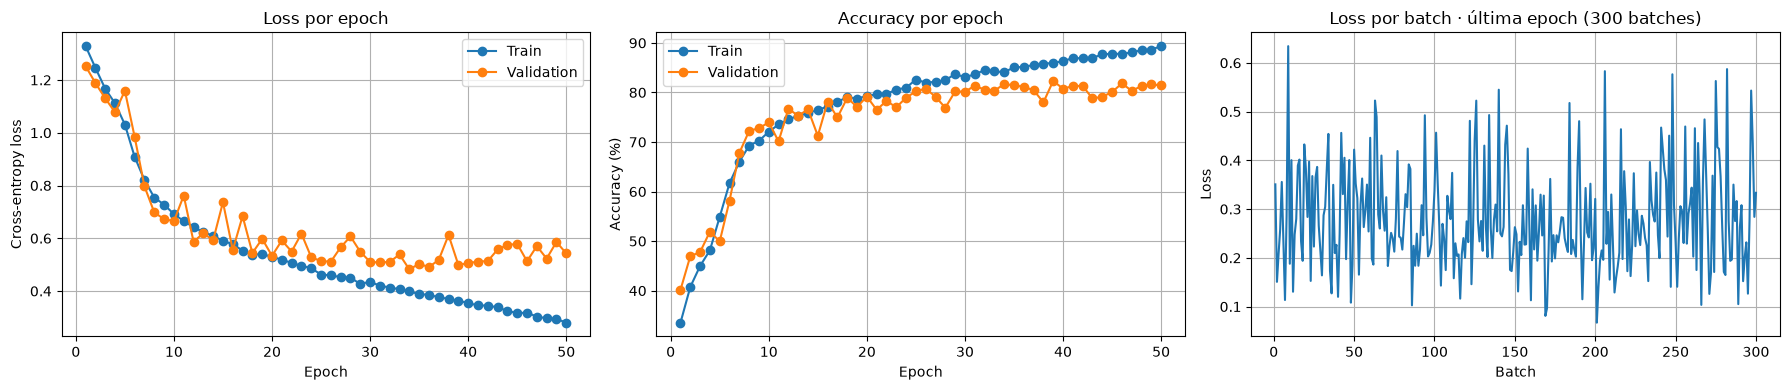

Mejor epoch según val loss: 34
Mejor val acc: 82.33% (epoch 39)
Diferencia train-val acc en la última epoch: 7.9 puntos


In [11]:
model = CNNBasica().to(DEVICE)

# ruta_prev = MODEL_DIR / "cnn_emociones_mejor.pt"
# ckpt = torch.load(ruta_prev, map_location=DEVICE)
# model.load_state_dict(ckpt["model_state_dict"])

history = train_model(
    model,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    lr=LEARNING_RATE
)

ep = np.arange(1, len(history["train_loss"]) + 1)
batch = history["batch_loss"][-1]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(ep, history["train_loss"], marker="o", label="Train")
axes[0].plot(ep, history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss por epoch")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy loss")

axes[1].plot(ep, history["train_acc"], marker="o", label="Train")
axes[1].plot(ep, history["val_acc"], marker="o", label="Validation")
axes[1].set_title("Accuracy por epoch")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)")

axes[2].plot(np.arange(1, len(batch) + 1), batch)
axes[2].set_title(f"Loss por batch · última epoch ({len(batch)} batches)")
axes[2].set_xlabel("Batch"); axes[2].set_ylabel("Loss")

for ax in axes:
    ax.grid(True)
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.show()

mejor_epoch = int(np.argmin(history["val_loss"])) + 1
print("Mejor epoch según val loss:", mejor_epoch)
print(f"Mejor val acc: {max(history['val_acc']):.2f}% "
      f"(epoch {int(np.argmax(history['val_acc'])) + 1})")
print(f"Diferencia train-val acc en la última epoch: "
      f"{history['train_acc'][-1] - history['val_acc'][-1]:.1f} puntos")

## MATRIZ DE CONFUSIÓN

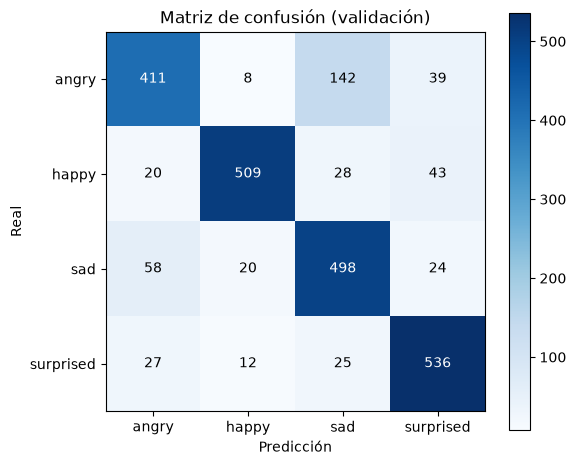

angry     : 68.5% de acierto
happy     : 84.8% de acierto
sad       : 83.0% de acierto
surprised : 89.3% de acierto


In [12]:
model.eval()
clases = train_ds.classes
n = len(clases)
matriz = np.zeros((n, n), dtype=int)

with torch.no_grad():
    for inputs, labels in val_loader:
        preds = model(inputs.to(DEVICE)).argmax(dim=1).cpu()
        for real, pred in zip(labels, preds):
            matriz[real, pred] += 1

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(matriz, cmap="Blues")
ax.set_xticks(range(n)); ax.set_xticklabels(clases)
ax.set_yticks(range(n)); ax.set_yticklabels(clases)
ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
for i in range(n):
    for j in range(n):
        ax.text(j, i, matriz[i, j], ha="center", va="center",
                color="white" if matriz[i, j] > matriz.max() / 2 else "black")
plt.colorbar(im); plt.title("Matriz de confusión (validación)")
plt.tight_layout(); plt.show()

for i, c in enumerate(clases):
    print(f"{c:10s}: {100 * matriz[i, i] / matriz[i].sum():.1f}% de acierto")